In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")


In [2]:

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = (
    project_root / "data" / "processed"
    / "eligible_purchases.parquet"
)

purchases_df = pd.read_parquet(data_path)

print("Dataset shape:", purchases_df.shape)
display(purchases_df.head())


Dataset shape: (805549, 11)


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,missing_customer,line_revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,30.0


In [3]:

snapshot_date = pd.Timestamp("2011-09-01")

historical_df = purchases_df.loc[
    purchases_df["invoice_date"] < snapshot_date
].copy()

print("Historical purchase lines:", len(historical_df))
print(
    "Historical customers:",
    historical_df["customer_id"].nunique()
)


Historical purchase lines: 634131
Historical customers: 5249


In [4]:

rfm = historical_df.groupby("customer_id").agg(
    last_purchase=("invoice_date", "max"),
    frequency=("invoice_no", "nunique"),
    monetary=("line_revenue", "sum"),
    product_diversity=("stock_code", "nunique")
)

rfm["recency_days"] = (
    snapshot_date - rfm["last_purchase"]
).dt.total_seconds() / 86400

rfm["avg_basket_value"] = (
    rfm["monetary"] / rfm["frequency"]
)

rfm = rfm.reset_index()

display(rfm.head())


,customer_id,last_purchase,frequency,monetary,product_diversity,recency_days,avg_basket_value
0,12346,2011-01-18 10:01:00,12,77556.46,27,225.582639,6463.038333
1,12347,2011-08-02 08:48:00,6,4114.18,107,29.633333,685.696667
2,12348,2011-04-05 10:47:00,4,1709.40,25,148.550694,427.350000
3,12349,2010-10-28 08:23:00,3,2671.14,90,307.650694,890.380000
4,12350,2011-02-02 16:01:00,1,334.40,17,210.332639,334.400000


In [6]:

prediction_end = snapshot_date + pd.Timedelta(days=30)

future_df = purchases_df.loc[
    (purchases_df["invoice_date"] >= snapshot_date)
    & (purchases_df["invoice_date"] < prediction_end)
]

future_customers = set(future_df["customer_id"])

rfm["purchased_next_30d"] = (
    rfm["customer_id"]
    .isin(future_customers)
    .astype(int)
)

print("Customer records:", len(rfm))

print("\nTarget distribution:")
display(rfm["purchased_next_30d"].value_counts())

print("\nTarget percentages:")
display(
    rfm["purchased_next_30d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Customer records: 5249

Target distribution:


purchased_next_30d
0    4172
1    1077
Name: count, dtype: int64


Target percentages:


purchased_next_30d
0    79.48
1    20.52
Name: proportion, dtype: float64

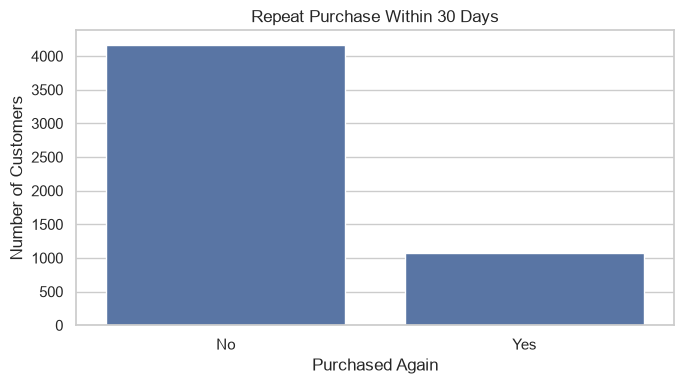

In [7]:

plt.figure(figsize=(7, 4))

sns.countplot(
    data=rfm,
    x="purchased_next_30d"
)

plt.title("Repeat Purchase Within 30 Days")
plt.xlabel("Purchased Again")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()


In [8]:

features = [
    "recency_days",
    "frequency",
    "monetary",
    "product_diversity",
    "avg_basket_value"
]

display(
    rfm[features].describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
    ).T.round(2)
)


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
recency_days,5249.0,204.46,171.39,0.28,49.51,161.42,317.58,469.30,540.68,630.32,638.59
frequency,5249.0,5.69,11.31,1.00,1.00,3.00,6.00,12.00,19.00,42.00,303.00
monetary,5249.0,2680.75,12384.33,2.90,323.25,804.02,2106.65,5120.67,8605.92,27880.68,479701.58
product_diversity,5249.0,73.91,104.24,1.00,17.00,41.00,91.00,177.00,255.60,452.80,2168.00
avg_basket_value,5249.0,378.15,543.40,2.90,179.40,283.89,421.25,659.13,911.52,1997.06,14844.77


In [9]:

comparison = (
    rfm.groupby("purchased_next_30d")[features]
    .median()
    .T
)

comparison.columns = [
    "Did Not Purchase",
    "Purchased Again"
]

display(comparison.round(2))


,Did Not Purchase,Purchased Again
recency_days,219.00,47.51
frequency,2.00,7.00
monetary,627.24,2393.47
product_diversity,34.00,87.00
avg_basket_value,267.46,339.90


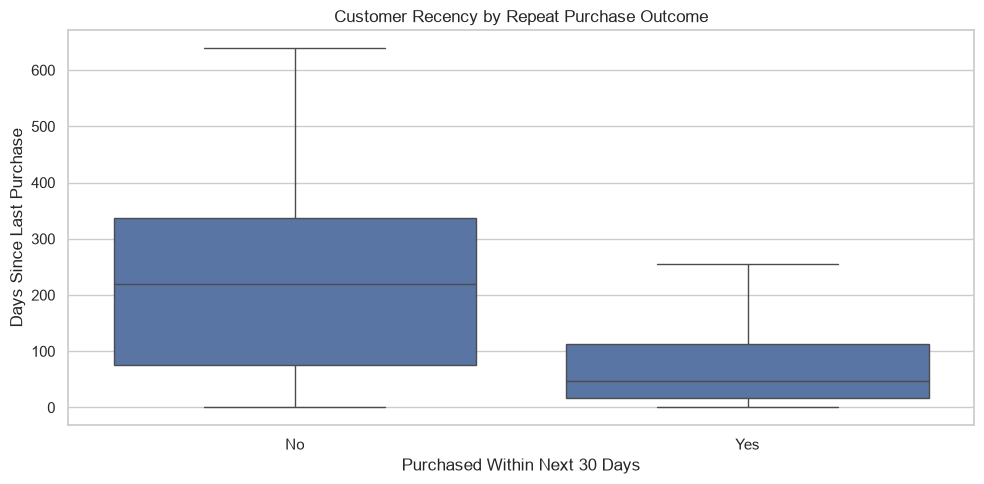

In [12]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=rfm,
    x="purchased_next_30d",
    y="recency_days",
    showfliers=False
)

plt.title("Customer Recency by Repeat Purchase Outcome")
plt.xlabel("Purchased Within Next 30 Days")
plt.ylabel("Days Since Last Purchase")
plt.xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()


In [13]:

output_path = (
    project_root / "data" / "processed"
    / "customer_features.parquet"
)

rfm.to_parquet(output_path, index=False)

print("Customer features saved successfully!")
print("Shape:", rfm.shape)


Customer features saved successfully!
Shape: (5249, 8)
